# 06 — OD Reliability & Trip-Purpose Diagnostics
**Toronto Bike Share · June 2024 · Guo-inspired behavioural quality assessment**

**Purpose.** Investigate the 249 flagged origin–destination (OD) pairs from Notebook 05 by checking station-location provenance and repeated-trip duration patterns before attributing any difference to inefficient travel or environmental exposure.

**Fundamental limit:** Bike Share data identify rental start/end stations and timestamps, not actual paths, stops or trip purpose. The labels produced here are **diagnostic patterns/hypotheses**, not verified trip purposes. A long rental may involve leisure, stops, a detour, docking, data errors or other circumstances. Environmental exposure along the modelled route must not be inferred from the excess rental duration.

**Inputs:** Existing June 2024 validated trip Parquet, OD summaries exported by Notebook 05, provisional station reference GPKG and (optionally) GraphHopper SQLite for contextual geometry. **No rerouting required.**

In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path('/scratch/project_2010417/paper3/toronto-bike-exposure')
DATA = ROOT / 'data/processed'
PREV = ROOT / 'outputs/guo_od_hotspots'
OUT = ROOT / 'outputs/guo_od_diagnostics'
OUT.mkdir(parents=True, exist_ok=True)
TRIPS = DATA / 'bikeshare_june_2024_validated.parquet'
STATIONS = DATA / 'bikeshare_station_reference_provisional.gpkg'
assert TRIPS.exists(), TRIPS
assert STATIONS.exists(), STATIONS
for filename in ['eligible_od_statistics_n20.csv','OD_quality_review_candidates.csv']:
    assert (PREV / filename).exists(), f'Missing {PREV / filename}; run Notebook 05 first.'
print('Output directory:', OUT)

Output directory: /scratch/project_2010417/paper3/toronto-bike-exposure/outputs/guo_od_diagnostics


## 1. Join station provenance to the flagged OD pairs
The 2023 and 2026 station snapshots are proxies, **not validation of June 2024 station positions**. Treat `coordinate_difference_m` as a movement/disagreement diagnostic, not proof of a historical move.

In [2]:
def norm(s):
    return s.astype('string').str.strip().str.replace(r'\.0+$','',regex=True)

review = pd.read_csv(PREV/'OD_quality_review_candidates.csv', dtype={
    'Start_Station_Id':'string','End_Station_Id':'string'
})
eligible = pd.read_csv(PREV/'eligible_od_statistics_n20.csv',dtype={
    'Start_Station_Id':'string','End_Station_Id':'string'
})
stations = gpd.read_file(STATIONS)
stations['station_id'] = norm(stations['station_id'])
assert not stations.station_id.duplicated().any(), 'Duplicate station IDs in station reference'
assert not review.duplicated(['Start_Station_Id','End_Station_Id']).any()
print('Flagged ODs:',len(review),'| stations:',len(stations))
print('Coordinate sources:',stations.coordinate_source.value_counts(dropna=False).to_dict())
print('Verified June 2024 locations:',stations.coordinate_verified_for_june_2024.value_counts(dropna=False).to_dict())

fields = ['station_id','coordinate_source','coordinate_difference_m',
          'location_review_required','coordinate_verified_for_june_2024','lat','lon',
          'name_2023','name_2026']
for side,col in [('start','Start_Station_Id'),('end','End_Station_Id')]:
    meta = stations[fields].rename(columns={c:f'{side}_{c}' for c in fields})
    review = review.merge(meta,left_on=col,right_on=f'{side}_station_id',
                          how='left',validate='many_to_one')
for side in ['start','end']:
    review[f'{side}_location_review_required'] = review[f'{side}_location_review_required'].fillna(True).astype(bool)
    # Unknown verification is not a positive verification.
    review[f'{side}_verified'] = review[f'{side}_coordinate_verified_for_june_2024'].fillna(False).astype(bool)
    review[f'{side}_move_m'] = pd.to_numeric(review[f'{side}_coordinate_difference_m'],errors='coerce')
review['station_missing'] = review[['start_station_id','end_station_id']].isna().any(axis=1)
review['location_review_any'] = review['start_location_review_required'] | review['end_location_review_required']
review['both_verified_june_2024'] = review['start_verified'] & review['end_verified']
review['max_snapshot_disagreement_m'] = review[['start_move_m','end_move_m']].max(axis=1)
review['location_concern'] = (
    review.station_missing | review.location_review_any |
    review.max_snapshot_disagreement_m.gt(50).fillna(False)
)
print('Flagged ODs with location concern:',int(review.location_concern.sum()),'of',len(review))
display(review[['Start_Station_Id','End_Station_Id','n','median_delta_min',
                'station_missing','max_snapshot_disagreement_m','location_review_any',
                'both_verified_june_2024']].head())

Flagged ODs: 249 | stations: 1116
Coordinate sources: {'2023_snapshot': 674, '2026_snapshot': 442}
Verified June 2024 locations: {False: 1116}
Flagged ODs with location concern: 50 of 249


,Start_Station_Id,End_Station_Id,n,median_delta_min,station_missing,max_snapshot_disagreement_m,location_review_any,both_verified_june_2024
0,7288,7514,128,4.504583,False,0.0,False,False
1,7175,7016,107,6.596750,False,0.0,False,False
2,7514,7289,95,13.306767,False,0.0,False,False
3,7514,7288,91,24.387917,False,0.0,False,False
4,7016,7175,83,5.580083,False,0.0,False,False


## 2. Inspect individual rental-duration distributions
Work with the flagged ODs only. This keeps the diagnostic sample small while retaining **all trips** on those pairs. The data-quality filter is the same as Notebook 05: recognised type, observed duration 1–90 minutes, modelled duration 0.5–90 minutes, modelled route ≥100 m, and positive duration. No new outlier trimming is introduced.

In [3]:
keys = ['Start_Station_Id','End_Station_Id']
cols = keys+['Trip_Duration','Start_Time','Bike_Model']
t = pd.read_parquet(TRIPS,columns=cols)
for col in keys: t[col]=norm(t[col])
t['observed_min'] = pd.to_numeric(t.Trip_Duration,errors='coerce')/60
t['started_at'] = pd.to_datetime(t.Start_Time,errors='coerce')
bm = t.Bike_Model.astype('string').str.strip().str.upper()
t['bike_type'] = np.select([bm.str.startswith('EFIT',na=False),bm.eq('ICONIC').fillna(False)],
                           ['Electric','Conventional'],default='Unknown')
# Join only flagged OD trips to already exported OD modelling statistics.
base = review[keys+['n','distance_m','modelled_min','median_delta_min','iqr_observed_min']].copy()
base = base.rename(columns={'n':'n_previous'})
t = t.merge(base,on=keys,how='inner',validate='many_to_one')
t = t.loc[t.observed_min.between(1,90)&t.modelled_min.between(.5,90)&
          t.distance_m.ge(100)&t.started_at.notna()&
          t.bike_type.isin(['Electric','Conventional'])].copy()
t['delta_min'] = t.observed_min-t.modelled_min
t['hour'] = t.started_at.dt.hour
t['weekend'] = t.started_at.dt.dayofweek.ge(5)
t['day'] = t.started_at.dt.normalize()
print('Flagged OD rentals used:',len(t),'| represented flagged ODs:',t[keys].drop_duplicates().shape[0])
assert len(t)>0

Flagged OD rentals used: 8467 | represented flagged ODs: 249


## 3. Distribution diagnostics and plausible patterns
A within-OD multi-peaked or broad duration distribution is **consistent with** a mix of travel behaviours but does **not identify** individual trip purposes. We quantify p10/p50/p90, fraction of rentals >30 minutes, weekend percentage, evening percentage and proportion of recorded duration exceeding twice the model estimate.

The `long_rental_pattern` and `variable_duration_pattern` labels are **descriptive flags only**; `requires_station_review` overrides other labels when station provenance is uncertain.

In [4]:
def quantile(q):
    return lambda x: x.quantile(q)
summary = (t.groupby(keys,observed=True)
    .agg(n_observed=('observed_min','size'),
         p10_min=('observed_min',quantile(.10)),
         p25_min=('observed_min',quantile(.25)),
         p50_min=('observed_min','median'),
         p75_min=('observed_min',quantile(.75)),
         p90_min=('observed_min',quantile(.90)),
         share_over_30min=('observed_min',lambda x:(x>30).mean()),
         share_weekend=('weekend','mean'),
         share_evening=('hour',lambda x:x.between(18,23).mean()),
         share_over_2x_model=('delta_min',lambda x:np.nan),
         share_electric=('bike_type',lambda x:(x=='Electric').mean()),
         unique_days=('day','nunique'))
    .reset_index())
# Compute doubled-model prevalence from individual rentals (modelled time constant per OD).
t['more_than_2x_model'] = t.observed_min > 2*t.modelled_min
share2 = t.groupby(keys,observed=True).more_than_2x_model.mean().rename('actual_share_2x').reset_index()
summary = summary.drop(columns='share_over_2x_model').merge(share2,on=keys,validate='one_to_one')
summary['iqr_min'] = summary.p75_min-summary.p25_min
summary['p90_p10_span_min'] = summary.p90_min-summary.p10_min
review2 = review.merge(summary,on=keys,how='left',validate='one_to_one')
# Use the previous analysis flags, and conservative review-first logic.
review2['diagnostic_pattern'] = np.select([
    review2.location_concern,
    review2.p50_min.ge(30)&review2.actual_share_2x.ge(.75),
    review2.iqr_min.ge(15),
    review2.p50_min.sub(review2.modelled_min).ge(15),
],['requires_station_review','long_rental_pattern','variable_duration_pattern',
   'large_model_relative_difference'],default='other_or_mixed_pattern')
print(review2.diagnostic_pattern.value_counts(dropna=False).to_string())
print('Important: these are pattern labels, NOT inferred rider purposes.')
display(review2.sort_values('median_delta_min',ascending=False)[
    keys+['n_observed','distance_m','modelled_min','p10_min','p50_min','p90_min',
          'iqr_min','actual_share_2x','share_weekend',
          'max_snapshot_disagreement_m','diagnostic_pattern']].head(15).round(2))
review2.to_csv(OUT/'flagged_od_station_and_duration_diagnostics.csv',index=False)

diagnostic_pattern
variable_duration_pattern          178
requires_station_review             50
long_rental_pattern                 11
other_or_mixed_pattern               9
large_model_relative_difference      1
Important: these are pattern labels, NOT inferred rider purposes.


,Start_Station_Id,End_Station_Id,n_observed,distance_m,modelled_min,p10_min,p50_min,p90_min,iqr_min,actual_share_2x,share_weekend,max_snapshot_disagreement_m,diagnostic_pattern
141,7222,7518,26,272.82,0.91,3.12,48.69,65.51,27.88,0.92,0.50,0.00,long_rental_pattern
142,7616,7626,26,354.24,3.56,26.85,50.45,71.62,20.65,1.00,0.69,0.00,long_rental_pattern
211,7626,7616,21,354.24,3.56,9.50,45.63,62.90,33.88,0.95,0.62,0.00,long_rental_pattern
156,7377,7709,25,424.46,1.54,3.96,42.32,57.64,20.45,0.88,0.40,49.71,requires_station_review
200,7288,7838,22,422.36,1.77,3.61,42.47,81.23,51.85,0.86,0.32,0.00,long_rental_pattern
179,7175,7018,23,718.45,3.97,5.51,42.18,57.06,41.95,0.78,0.57,0.00,long_rental_pattern
98,7794,7076,31,184.42,1.57,2.07,38.05,50.38,29.19,0.84,0.52,51.02,requires_station_review
123,7220,7225,28,322.61,1.39,11.93,36.48,65.56,32.73,0.96,0.32,0.00,long_rental_pattern
15,7822,7354,62,655.35,2.18,4.06,36.14,73.96,58.05,0.84,0.55,0.00,long_rental_pattern
89,7609,7608,33,545.05,2.04,13.66,33.33,83.67,36.10,0.94,0.48,0.00,long_rental_pattern


## 4. Inspect the top eight extreme pairs individually
Histograms show complete (quality-filtered) rental-time distributions and the modelled OD time. These are **observed rental times**, not continuously observed cycling times.

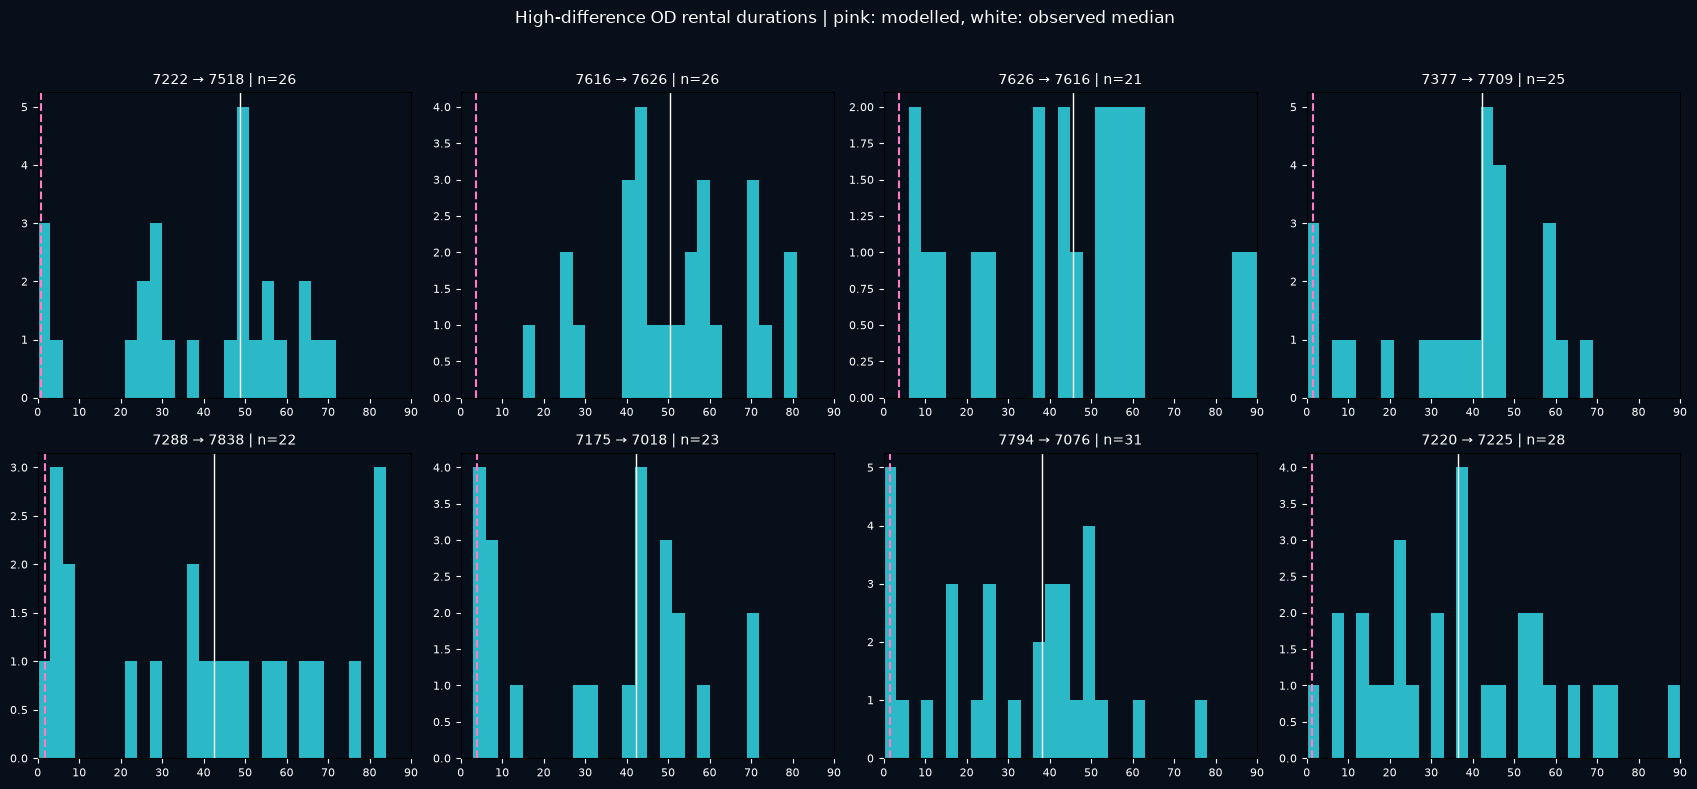

In [5]:
ranked = review2.sort_values(['median_delta_min','n_observed'],ascending=[False,False]).head(8)
fig,axes=plt.subplots(2,4,figsize=(17,8),facecolor='#07101a')
for ax,(_,rec) in zip(axes.flat,ranked.iterrows()):
    sub=t[(t.Start_Station_Id==rec.Start_Station_Id)&
          (t.End_Station_Id==rec.End_Station_Id)]
    ax.set_facecolor('#07101a')
    ax.hist(sub.observed_min,bins=np.arange(0,92,3),color='#32d8e6',alpha=.85)
    ax.axvline(rec.modelled_min,color='#ff7bc6',ls='--',lw=1.5)
    ax.axvline(sub.observed_min.median(),color='white',lw=1)
    ax.set_title(f'{rec.Start_Station_Id} → {rec.End_Station_Id} | n={len(sub)}',color='white',fontsize=10)
    ax.tick_params(colors='white',labelsize=8)
    ax.set_xlim(0,90)
fig.suptitle('High-difference OD rental durations | pink: modelled, white: observed median',color='white')
fig.tight_layout(rect=(0,0,1,.96))
fig.savefig(OUT/'figure_01_top8_duration_distributions.png',dpi=190,facecolor=fig.get_facecolor())
plt.show()

## 5. Separate station concerns from behavioural patterns
Compare location flags, snapshot-coordinate disagreement and typical differences. June-2024 coordinate verification is shown separately: lack of historical verification is a dataset-wide caveat, not by itself a reason to mark every OD as a location-specific anomaly.

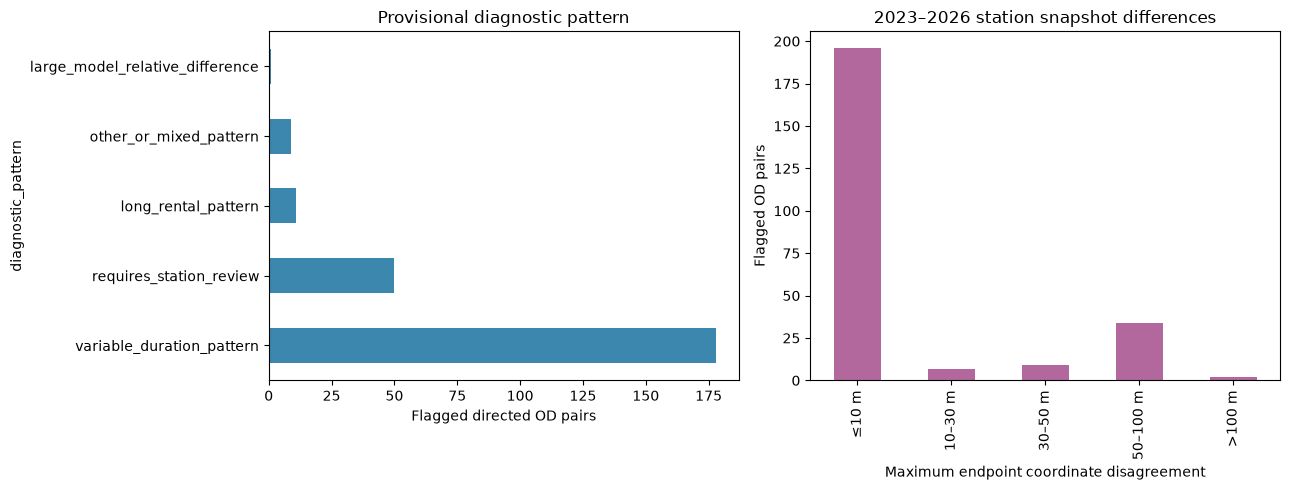

Any June 2024 verified OD endpoints: 0 of 249


In [6]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
review2.diagnostic_pattern.value_counts().plot.barh(ax=axes[0],color='#3b87ad')
axes[0].set(xlabel='Flagged directed OD pairs',title='Provisional diagnostic pattern')
loc=review2.copy()
loc['snapshot_band']=pd.cut(loc.max_snapshot_disagreement_m,
       bins=[-np.inf,10,30,50,100,np.inf],labels=['≤10 m','10–30 m','30–50 m','50–100 m','>100 m'])
loc.snapshot_band.value_counts(sort=False).plot.bar(ax=axes[1],color='#b2689c')
axes[1].set(xlabel='Maximum endpoint coordinate disagreement',ylabel='Flagged OD pairs',title='2023–2026 station snapshot differences')
fig.tight_layout();fig.savefig(OUT/'figure_02_station_uncertainty_and_patterns.png',dpi=190);plt.show()
print('Any June 2024 verified OD endpoints:',review2.both_verified_june_2024.sum(),
      'of',len(review2))

## 6. Sensitivity to distance and time-difference thresholds
Short-distance rentals can dominate apparent excess-time rankings. Re-rank using minimum modelled distances and review whether high-difference station pairs persist. Do **not** exclude short trips automatically from the source dataset.

,minimum_distance_m,candidate_ODs,top50_median_delta_min,top50_median_distance_m
0,0,5269,21.13,600.60
1,250,5245,20.01,629.44
2,500,5038,18.28,1101.68
3,1000,4009,13.20,3993.14
4,2000,1567,11.45,4990.58


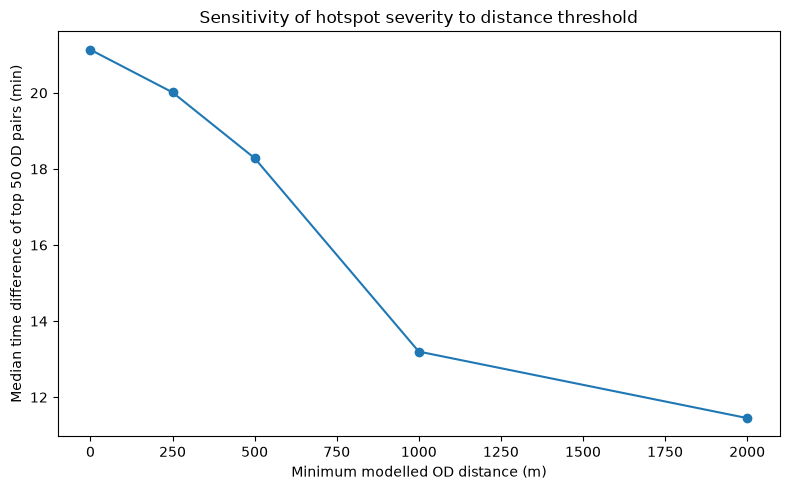

In [7]:
rows=[]
for min_distance in [0,250,500,1000,2000]:
    part=eligible.copy()
    part=part.loc[part.distance_m.ge(min_distance)]
    best=part.nlargest(50,'median_delta_min')
    rows.append({'minimum_distance_m':min_distance,'candidate_ODs':len(part),
                 'top50_median_delta_min':best.median_delta_min.median() if len(best) else np.nan,
                 'top50_median_distance_m':best.distance_m.median() if len(best) else np.nan})
sensitivity=pd.DataFrame(rows)
display(sensitivity.round(2))
sensitivity.to_csv(OUT/'distance_threshold_sensitivity.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
ax.plot(sensitivity.minimum_distance_m,sensitivity.top50_median_delta_min,marker='o')
ax.set(xlabel='Minimum modelled OD distance (m)',ylabel='Median time difference of top 50 OD pairs (min)',
       title='Sensitivity of hotspot severity to distance threshold')
fig.tight_layout();fig.savefig(OUT/'figure_03_distance_sensitivity.png',dpi=190);plt.show()

## 7. Departure-time / weekend patterns for selected OD pairs
Weekend-heavy and evening-heavy rental patterns might motivate a future trip-purpose survey, but they **do not establish** leisure, commuting or other purposes.

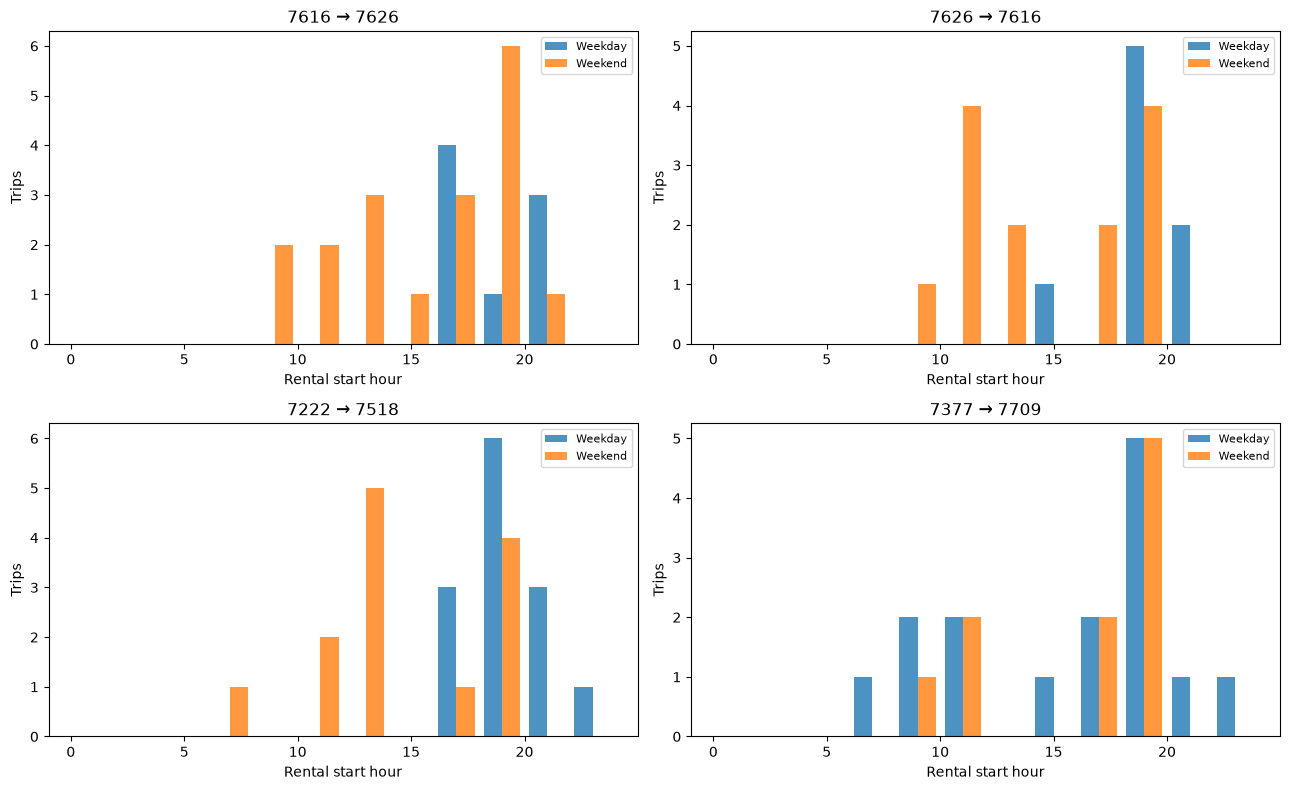

In [8]:
subset = ranked.head(4)[keys].copy()
plotdata=t.merge(subset,on=keys,how='inner')
plotdata['od_label']=plotdata.Start_Station_Id+' → '+plotdata.End_Station_Id
fig,axes=plt.subplots(2,2,figsize=(13,8))
for ax,(name,part) in zip(axes.flat,plotdata.groupby('od_label',sort=False)):
    ax.hist([part.loc[~part.weekend,'hour'],part.loc[part.weekend,'hour']],
            bins=np.arange(0,25,2),label=['Weekday','Weekend'],alpha=.8)
    ax.set(xlabel='Rental start hour',ylabel='Trips',title=name)
    ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'figure_04_departure_time_diagnostics.png',dpi=190);plt.show()

## 8. Optional station-only location map
Plotting station endpoints is safer than depicting their entire modelled paths as observed movement. Lines connect *stations*, not GPS trajectories. If endpoints are missing, omit them.

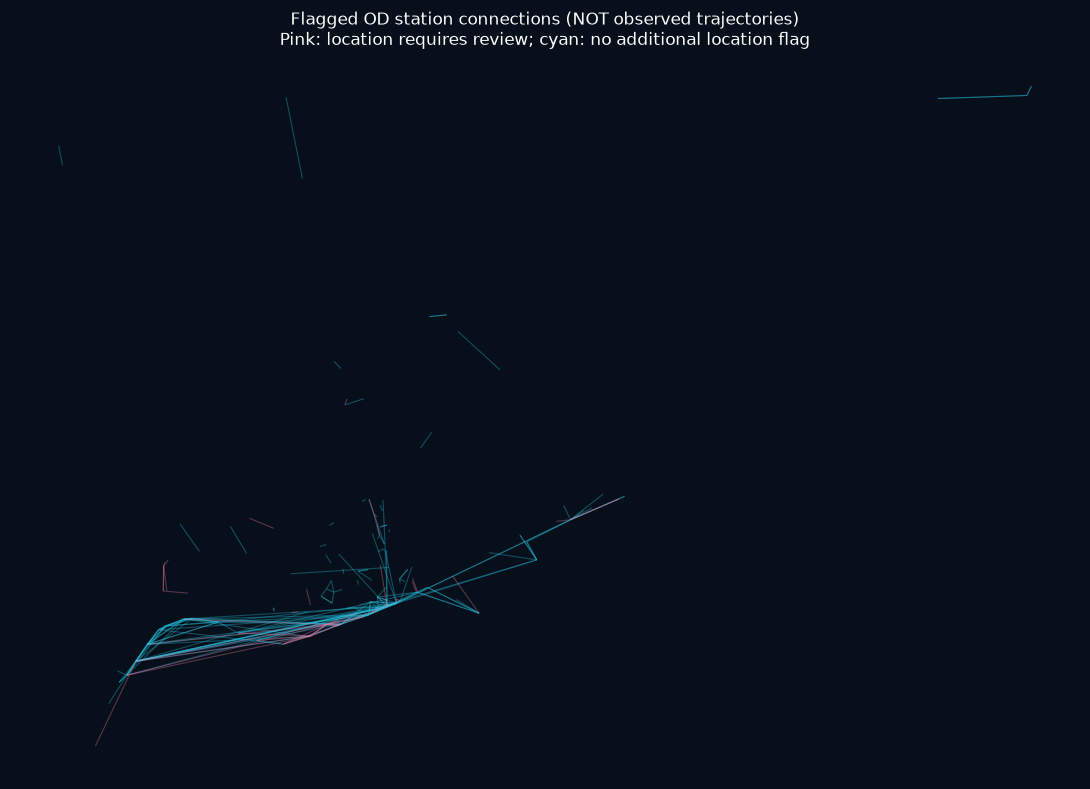

In [9]:
from shapely.geometry import Point, LineString
map_df=review2.dropna(subset=['start_lon','start_lat','end_lon','end_lat']).copy()
map_df['start_lon']=pd.to_numeric(map_df.start_lon,errors='coerce')
map_df['start_lat']=pd.to_numeric(map_df.start_lat,errors='coerce')
map_df['end_lon']=pd.to_numeric(map_df.end_lon,errors='coerce')
map_df['end_lat']=pd.to_numeric(map_df.end_lat,errors='coerce')
map_df=map_df.dropna(subset=['start_lon','start_lat','end_lon','end_lat'])
if len(map_df):
    geoms=[LineString([(r.start_lon,r.start_lat),(r.end_lon,r.end_lat)]) for r in map_df.itertuples()]
    gdf=gpd.GeoDataFrame(map_df,geometry=geoms,crs='EPSG:4326').to_crs('EPSG:26917')
    fig,ax=plt.subplots(figsize=(11,10),facecolor='#07101a')
    ax.set_facecolor('#07101a')
    if (~gdf.location_concern).any():
        gdf.loc[~gdf.location_concern].plot(ax=ax,color='#24c3e1',linewidth=.8,alpha=.35)
    if gdf.location_concern.any():
        gdf.loc[gdf.location_concern].plot(ax=ax,color='#f17aa8',linewidth=.8,alpha=.35)
    ax.set_axis_off()
    ax.set_title('Flagged OD station connections (NOT observed trajectories)\nPink: location requires review; cyan: no additional location flag',color='white')
    fig.tight_layout();fig.savefig(OUT/'map_05_station_connection_review.png',dpi=190,facecolor=fig.get_facecolor());plt.show()
else:
    print('No usable endpoint coordinates available for map.')

## 9. Ranked manual-review shortlist
The highest-priority cases combine **repeated observations**, large differences, high variability, potential station-location concerns, and suspiciously short modelled distance. The score is purely a **triage heuristic**, not a statistical probability, risk score or research finding.

In [10]:
rank=review2.copy()
rank['triage_score'] = (
    2*rank.location_review_any.astype(int) +
    2*rank.station_missing.astype(int) +
    2*rank.max_snapshot_disagreement_m.gt(50).fillna(False).astype(int) +
    2*rank.distance_m.lt(500).astype(int) +
    rank.median_delta_min.gt(20).astype(int) +
    rank.iqr_observed_min.gt(15).astype(int) +
    np.log1p(rank.n).fillna(0)/5
)
shortlist=rank.sort_values(['triage_score','n'],ascending=[False,False])
columns=keys+['n','distance_m','modelled_min','median_delta_min','iqr_observed_min',
              'max_snapshot_disagreement_m','start_coordinate_source',
              'end_coordinate_source','location_review_any','diagnostic_pattern','triage_score']
shortlist[columns].head(50).to_csv(OUT/'top50_manual_review_shortlist.csv',index=False)
display(shortlist[columns].head(20).round(2))
print('Saved all results to:',OUT)

,Start_Station_Id,End_Station_Id,n,distance_m,modelled_min,median_delta_min,iqr_observed_min,max_snapshot_disagreement_m,start_coordinate_source,end_coordinate_source,location_review_any,diagnostic_pattern,triage_score
98,7794,7076,31,184.42,1.57,36.48,29.19,51.02,2023_snapshot,2023_snapshot,True,requires_station_review,8.69
169,7224,7086,24,152.41,0.92,20.07,44.58,68.65,2023_snapshot,2023_snapshot,True,requires_station_review,8.64
201,7076,7794,22,184.42,1.57,28.87,58.68,51.02,2023_snapshot,2023_snapshot,True,requires_station_review,8.63
38,7707,7411,49,440.74,1.72,5.43,23.12,56.19,2023_snapshot,2023_snapshot,True,requires_station_review,7.78
101,7411,7707,31,440.74,1.80,9.89,41.06,56.19,2023_snapshot,2023_snapshot,True,requires_station_review,7.69
175,7654,7086,24,312.87,1.53,1.82,24.04,68.65,2023_snapshot,2023_snapshot,True,requires_station_review,7.64
182,7072,7707,23,375.76,2.51,11.65,39.36,56.19,2023_snapshot,2023_snapshot,True,requires_station_review,7.64
156,7377,7709,25,424.46,1.54,40.78,20.45,49.71,2023_snapshot,2023_snapshot,True,requires_station_review,6.65
13,7430,7569,65,2412.83,8.02,3.98,15.77,68.40,2023_snapshot,2023_snapshot,True,requires_station_review,5.84
14,7203,7569,64,1271.11,4.49,5.99,18.02,68.40,2023_snapshot,2023_snapshot,True,requires_station_review,5.83


Saved all results to: /scratch/project_2010417/paper3/toronto-bike-exposure/outputs/guo_od_diagnostics


## 10. Recommended next research decision
Inspect the top 10–20 cases manually, especially `7222→7518`, `7616↔7626` and `7377→7709` if present. Check both endpoint station names, historical location quality, bike type, full rental-time distributions, and weekday/weekend departures. Only then decide whether these should be excluded from a direct-route exposure proxy, classified as indeterminate, or studied through interviews / PPGIS.

**Strong caveat:** A *trip-purpose diagnostic* is not purpose classification. Without GPS trajectories or purpose surveys, the data cannot distinguish a commuting detour from a recreational ride or prolonged parking stop. For later exposure modelling, consider distinguishing **ambient concentration at trip endpoints / departure hour** from **hypothetical concentration–time along modelled routes**, and never assign all extra duration to the modelled route.